## Dog breeds classifier.
In this tasks you are supposed to build dog breeds classifier.
You may use materials of previous classes, chat gpt, anything.

Just get the maximum accuracy.

In [1]:
from glob import glob
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pickle as pkl
import uuid
from time import time

### Download the data

In [2]:
# Google golab or in any Unix OS you may do that:
!wget -O dogdata.zip "https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip?rlkey=esrxurxfr4fe50duknmab979a&st=aqjo6u4r&dl=1"
!unzip -q dogdata.zip -d dogdata
data_path = './dogdata'
# Or, you may download and extract file manually: https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip
# And provide the path to extracted data here:
# data_path = #'D:/Data/dogs'

--2026-11-25 13:25:05--  https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip?rlkey=esrxurxfr4fe50duknmab979a&st=aqjo6u4r&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.3.18, 2620:100:6018:18::a27d:312
Connecting to www.dropbox.com (www.dropbox.com)|162.125.3.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc499cfb6a08e45c284ca4e579d0.dl.dropboxusercontent.com/cd/0/inline/DMl9y1dPVy5vVrrznUQhNq3ibfIQaNAdy-ofD4G86S_Xrdo-m0sXTk8to96-ZrOrZpcy9s8qzg6lt57Z1Jbs2qQTfCwZgSh3L2l94x8GJdviJmv0K8QD7NOGDnDjwKfSi3tocLr7rTWOpjk9uhrkQJrn/file?dl=1# [following]
--2026-11-25 13:25:05--  https://uc499cfb6a08e45c284ca4e579d0.dl.dropboxusercontent.com/cd/0/inline/DMl9y1dPVy5vVrrznUQhNq3ibfIQaNAdy-ofD4G86S_Xrdo-m0sXTk8to96-ZrOrZpcy9s8qzg6lt57Z1Jbs2qQTfCwZgSh3L2l94x8GJdviJmv0K8QD7NOGDnDjwKfSi3tocLr7rTWOpjk9uhrkQJrn/file?dl=1
Resolving uc499cfb6a08e45c284ca4e579d0.dl.dropboxusercontent.com (uc499cfb6a08e45c284ca4e579d0.dl.dropboxusercontent.co

### Read labels and filenames

In [3]:
fns = []
y = []
for lp in glob(f'{data_path}/train/*'):
    label = os.path.basename(lp)
    for fn in glob(f'{lp}/*'):
        fns.append(fn)
        y.append(label)
fns = np.array(fns)
y = np.array(y)

fns_submit = glob(f'{data_path}/test/*')

### Here are several examples:

chow


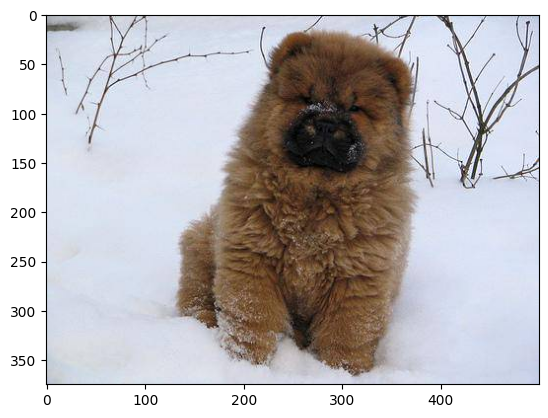

papillon


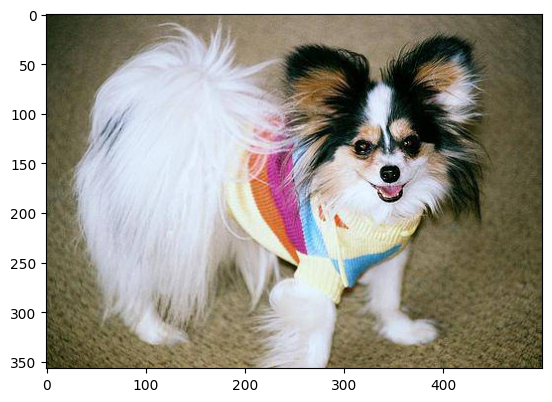

giant_schnauzer


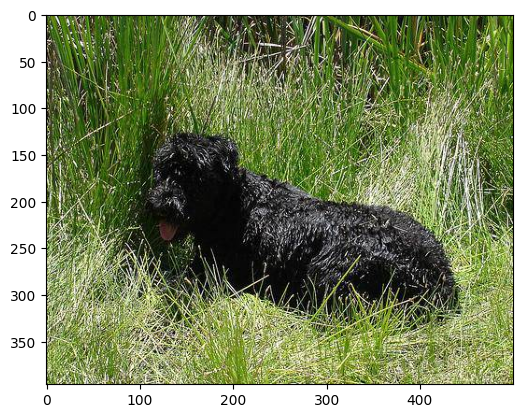

english_setter


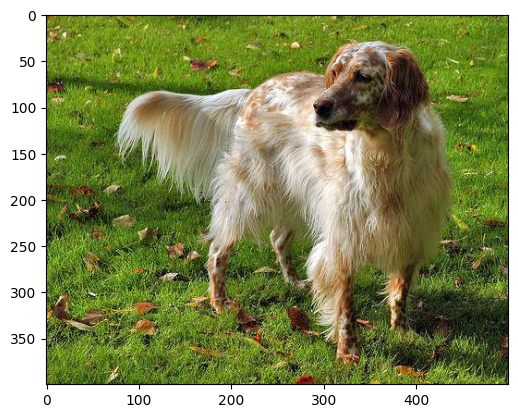

great_pyrenees


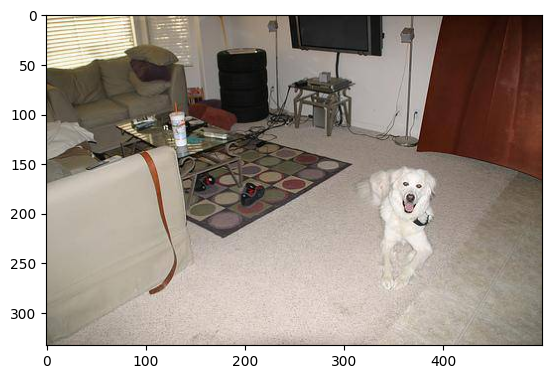

In [4]:
for label in list(set(y))[:5]:
    print(label)
    img = cv2.imread(fns[y == label][0])
    plt.imshow(img[:,:,::-1])
    plt.show()

# Your code goes here:

## Check the Data

train: 9022  test: 1200  classes: 120
min     56.0
50%     72.0
max    116.0
Name: count, dtype: float64


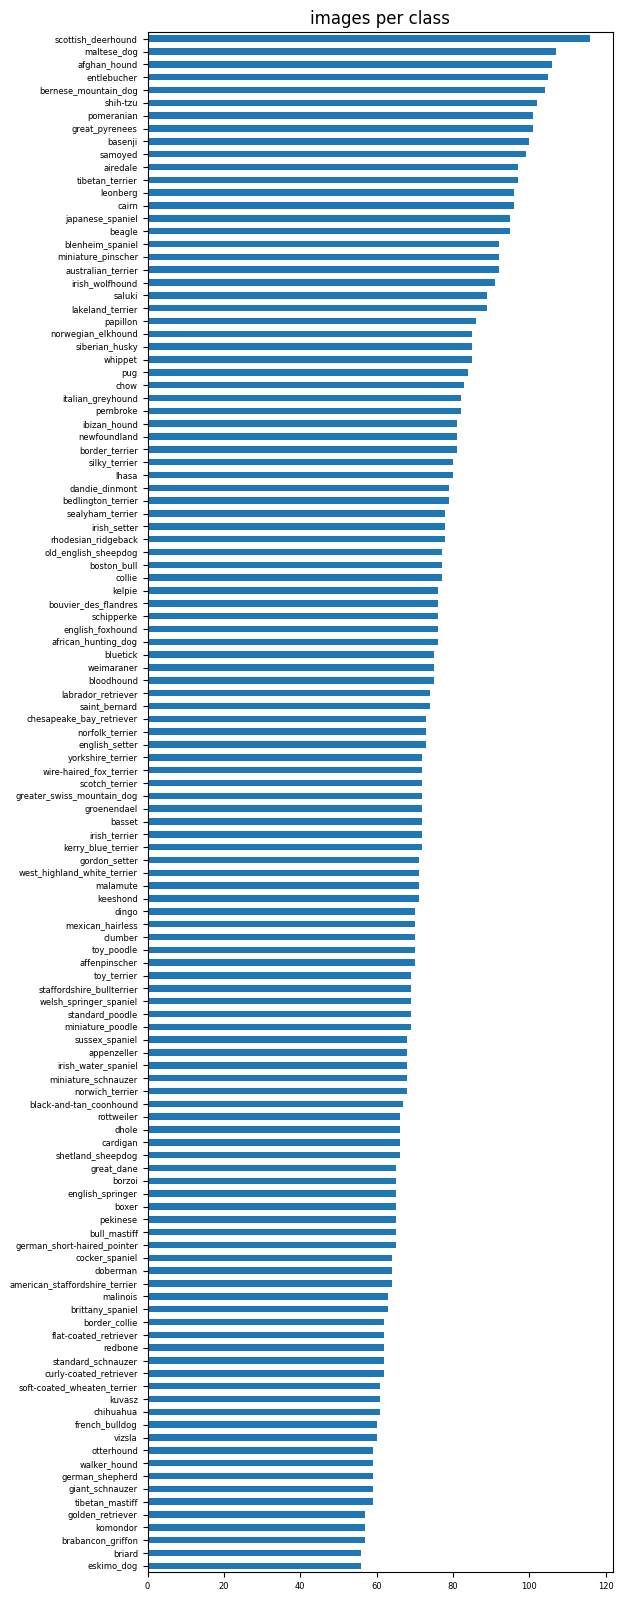

In [5]:
import pandas as pd
from PIL import Image

# 1) How many images / classes, and are classes balanced?
classes = np.unique(y)
counts = pd.Series(y).value_counts()
print(f'train: {len(fns)}  test: {len(fns_submit)}  classes: {len(classes)}')
print(counts.describe()[['min', '50%', 'max']])

counts.sort_values().plot.barh(figsize=(6, 20), fontsize=6, title='images per class')
plt.show()

split            test    train
w      count  1200.00  9022.00
       mean    444.70   443.15
       std     151.55   152.54
       min     110.00    97.00
       25%     356.25   360.00
       50%     500.00   500.00
       75%     500.00   500.00
       max    2560.00  3264.00
h      count  1200.00  9022.00
       mean    387.06   386.71
       std     136.17   129.24
       min     122.00   102.00
       25%     333.00   333.00
       50%     375.00   375.00
       75%     450.00   453.75
       max    1920.00  2562.00
aspect count  1200.00  9022.00
       mean      1.19     1.19
       std       0.30     0.30
       min       0.44     0.39
       25%       0.93     0.93
       50%       1.33     1.33
       75%       1.34     1.34
       max       2.23     2.60
split  mode
test   RGB     1200
train  RGB     9022
Name: count, dtype: int64


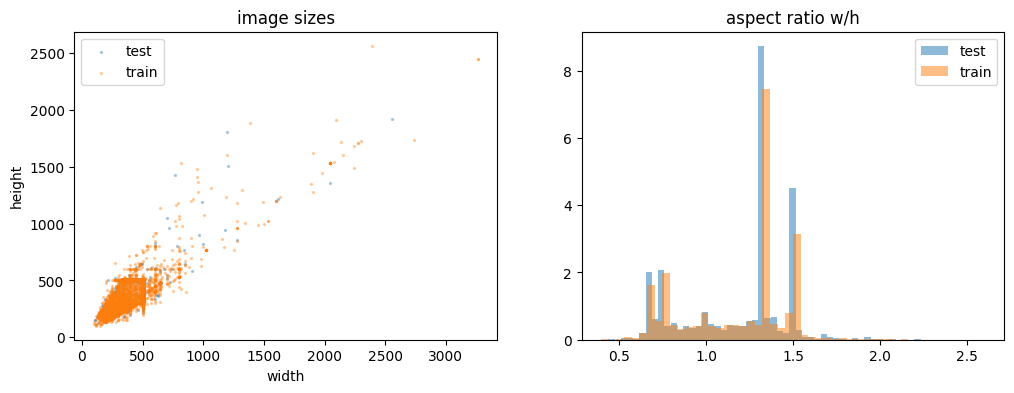

In [6]:
# 2) Image sizes, aspect ratio, color mode, broken files (train vs test)
def img_info(fn):
    try:
        with Image.open(fn) as im:  # reads header only -> fast
            return im.size[0], im.size[1], im.mode
    except Exception:
        return None, None, 'broken'

info = pd.DataFrame([img_info(f) for f in fns] + [img_info(f) for f in fns_submit], columns=['w', 'h', 'mode'])

info['split'] = ['train'] * len(fns) + ['test'] * len(fns_submit)
info['aspect'] = info.w / info.h

print(info.groupby('split')[['w', 'h', 'aspect']].describe().T.round(2))
print(info.groupby('split')['mode'].value_counts())  # non-RGB -> need .convert('RGB')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, d in info.groupby('split'):
    ax[0].scatter(d.w, d.h, s=2, alpha=0.3, label=s)
    ax[1].hist(d.aspect, bins=50, alpha=0.5, density=True, label=s)
ax[0].set(xlabel='width', ylabel='height', title='image sizes'); ax[0].legend()
ax[1].set(title='aspect ratio w/h'); ax[1].legend()
plt.show()

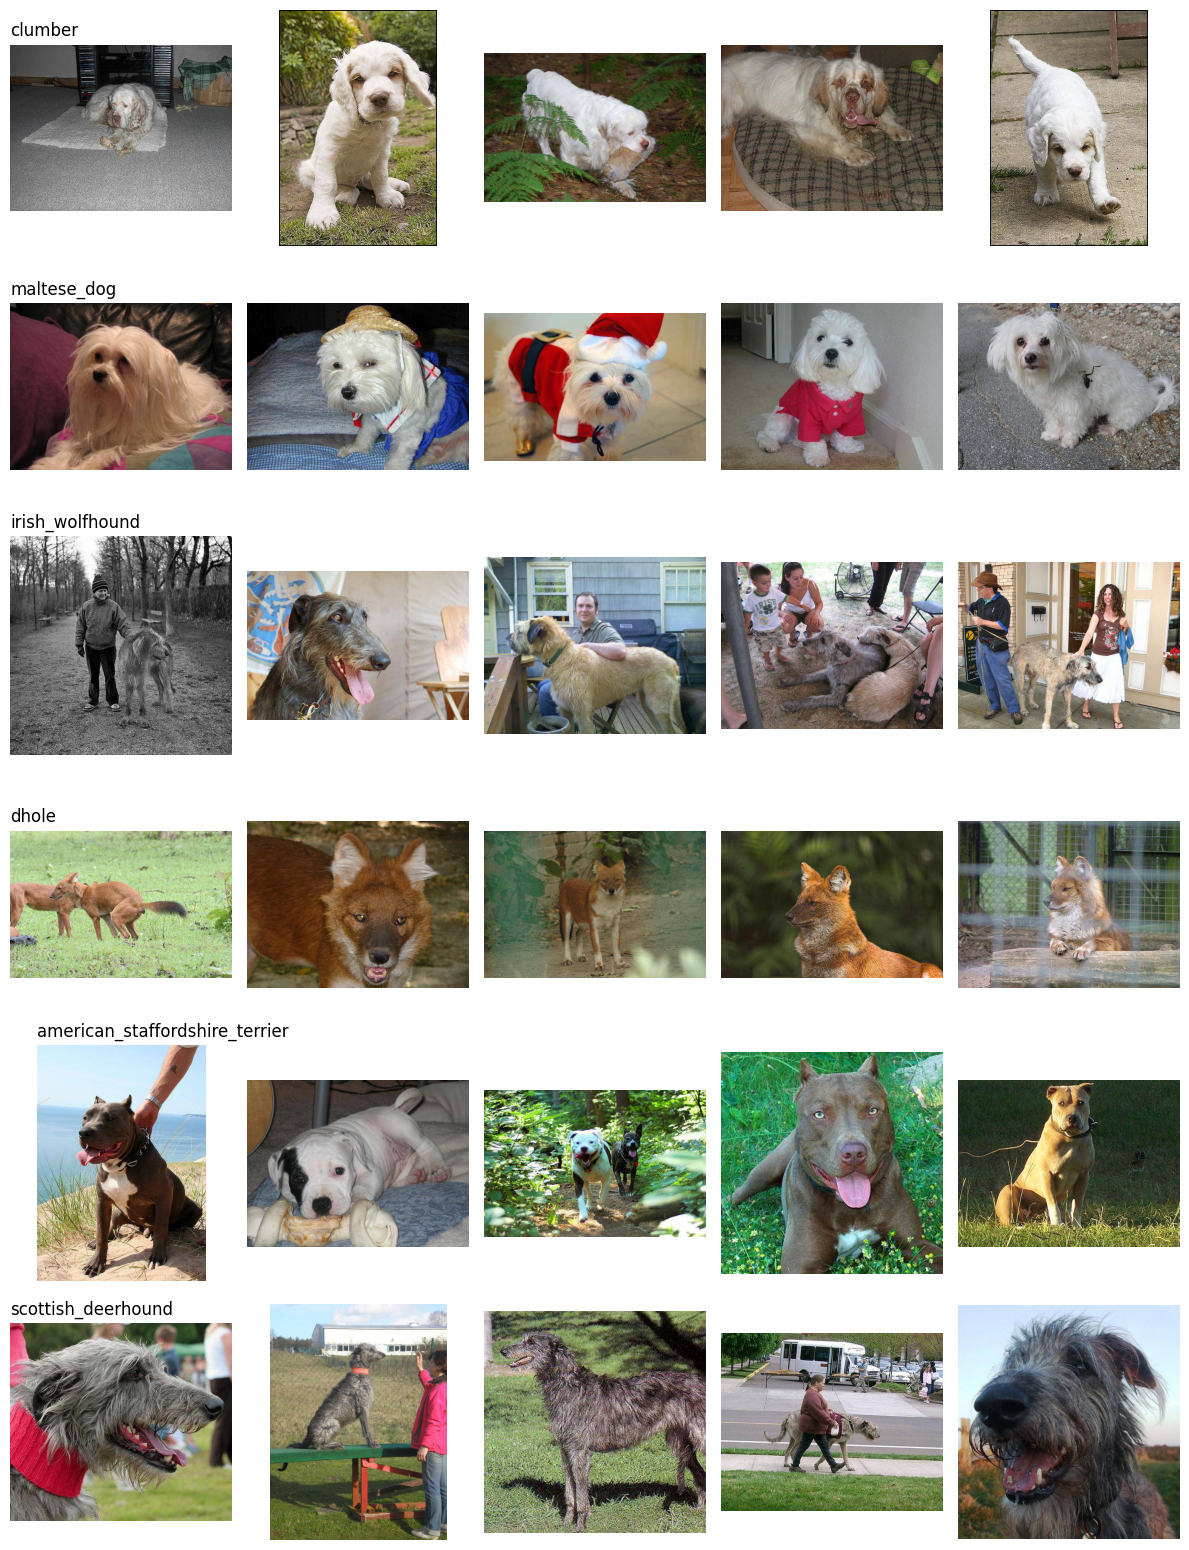

In [7]:
# 3) Eyeball: 5 random images for 6 random breeds (dog size, background, other objects/people, crops)
rng = np.random.default_rng(0)
show = rng.choice(classes, 6, replace=False)
fig, axes = plt.subplots(len(show), 5, figsize=(12, 2.6 * len(show)))
for row, label in zip(axes, show):
    for ax, fn in zip(row, rng.choice(fns[y == label], 5, replace=False)):
        ax.imshow(Image.open(fn).convert('RGB')); ax.axis('off')
    row[0].set_title(label, loc='left')
plt.tight_layout(); plt.show()

## Resnet50_pretain

torch.Size([64, 3, 224, 224]) torch.float32 tensor([ 21,  30,  39,  55, 104,  30,  34,  76])


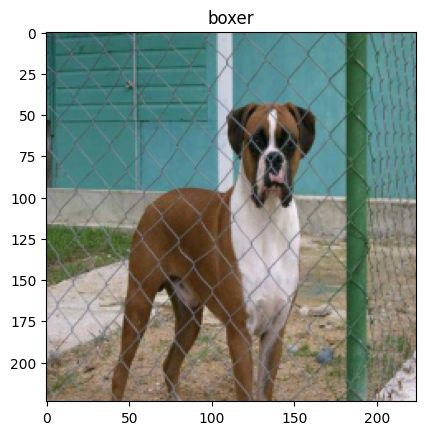

In [25]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split

# map class2idx
cls2idx = {c: i for i, c in enumerate(classes)}
y_idx = np.array([cls2idx[c] for c in y])


X_train, X_val, y_train, y_val = train_test_split(fns, y_idx, stratify=y_idx, test_size=0.2, random_state=67)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

def load_rgb(fn):
    return Image.open(fn).convert('RGB')

if 'IMG_CACHE' not in globals():  # skip the ~20 s preload when re-running this cell
    with ThreadPoolExecutor(4) as ex:  # PIL releases the GIL while decoding, so threads use both cores
        IMG_CACHE = dict(zip(fns, ex.map(load_rgb, fns)))
    print(f"cached {len(IMG_CACHE)} images in RAM: {sum(im.width * im.height * 3 for im in IMG_CACHE.values()) / 1e9:.1f} GB")

class DogDataset(Dataset):
    def __init__(self, fns, labels=None, tf=None):
        self.X = fns
        self.labels = labels
        self.tf = tf

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        fn = self.X[i]
        img = IMG_CACHE[fn] if fn in IMG_CACHE else load_rgb(fn)
        label = -1 if self.labels is None else self.labels[i]

        if self.tf is not None:
            img = self.tf(img)

        return img, label  

BS = 64
LOADER_OPTS = dict(num_workers=2, pin_memory=True, persistent_workers=False)
train_dl = DataLoader(DogDataset(X_train, y_train, train_tf), batch_size=BS, shuffle=True, **LOADER_OPTS)
val_dl = DataLoader(DogDataset(X_val, y_val, val_tf), batch_size=BS, **LOADER_OPTS)
test_dl = DataLoader(DogDataset(fns_submit, None, val_tf), batch_size=BS, num_workers=2)

# --- 5) Sanity check: shapes + one image undone back to normal colors ---
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb[:8])  # expect torch.Size([64, 3, 224, 224]) torch.float32
img = xb[0].permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
plt.imshow(img.clamp(0, 1)); plt.title(classes[yb[0].item()]); plt.show()  # dog looks normal + title matches?
    

In [26]:
from time import time
from tqdm import tqdm
import torch.nn as nn

LOSS_FN = nn.CrossEntropyLoss(label_smoothing=0.1)

def train_one_epoch(model, dl, opt, scaler):
    device = next(model.parameters()).device
    start_time = time()

    model.train()
    total_loss = 0
    for xb, yb in tqdm(dl, desc="training..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        yb = yb.to(device, non_blocking=True)

        opt.zero_grad()
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(xb)
            loss = LOSS_FN(logits, yb)
        scaler.scale(loss).backward()  # scaling keeps small fp16 gradients from rounding to zero
        scaler.step(opt)
        scaler.update()

        total_loss += loss.item()
    elapsed = time() - start_time

    print(f"train loss: {total_loss / len(dl):.3f} used {elapsed:.0f}s")
    return total_loss / len(dl)

@torch.no_grad()
def evaluate_model(model, dl):
    device = next(model.parameters()).device
    model.eval()
    total_loss, correct = 0, 0
    for xb, yb in tqdm(dl, desc="evaluating..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        yb = yb.to(device, non_blocking=True)

        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(xb)
            loss = LOSS_FN(logits, yb)
        total_loss += loss.item()

        correct += (logits.argmax(1) == yb).sum().item()
    acc = correct / len(dl.dataset)

    print(f"val loss: {total_loss / len(dl):.3f} val acc: {acc:.4f}")
    return total_loss / len(dl), acc

In [40]:
import copy
import hashlib, json
from torch.utils.tensorboard import SummaryWriter
from IPython.display import display

# AI
CKPT_DIR = 'checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

def loader_key(dl):
    return dict(tf=repr(dl.dataset.tf), batch_size=dl.batch_size,
                files=hashlib.md5(''.join(dl.dataset.X).encode()).hexdigest())

def live_plot(hist, handle=None):
    """Draw loss and val acc curves; update the same output each epoch via the display handle."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3))
    x = range(1, len(hist['val_acc']) + 1)
    ax_loss.plot(x, hist['train_loss'], label='train'); ax_loss.plot(x, hist['val_loss'], label='val')
    ax_acc.plot(x, hist['val_acc'])
    ax_loss.set_title('loss'); ax_acc.set_title('val acc'); ax_loss.legend()
    plt.close(fig)  # otherwise Jupyter draws a second copy when the cell ends
    if handle is None:
        return display(fig, display_id=True)
    handle.update(fig)
    return handle

def run_experiment(name, model, train_dl, val_dl, epochs, lr, version=1, patience=None):
    
    key = dict(name=name, epochs=epochs, lr=lr, data=loader_key(train_dl), version=version)
    if patience is not None:  # added only when set, so Checkpoints trained before early stopping keep their key
        key['patience'] = patience
    
    path = os.path.join(CKPT_DIR, f"{name}_{hashlib.md5(json.dumps(key, sort_keys=True).encode()).hexdigest()[:10]}.pt")
    
    device = next(model.parameters()).device
    model.to(memory_format=torch.channels_last) 
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"cache hit: loaded {path}, training skipped")
        return evaluate_model(model, val_dl)[1]

    head_name = [n for n, m in model.named_modules() if isinstance(m, nn.Linear)][-1]
    head = list(model.get_submodule(head_name).parameters())
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith(head_name + '.')]
    opt = torch.optim.AdamW([
        {"params": backbone, "lr": lr},
        {"params": head, "lr": 1e-3},
    ], weight_decay=0.05)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    best_acc, best_state, bad_epochs = -1.0, None, 0
    hist, plot = dict(train_loss=[], val_loss=[], val_acc=[]), None
    log_dir = os.path.join('runs', os.path.splitext(os.path.basename(path))[0])  # one log dir per Checkpoint
    with SummaryWriter(log_dir) as writer:
        for epoch in range(epochs):
            print(f"epoch {epoch + 1}/{epochs}")
            train_loss = train_one_epoch(model, train_dl, opt, scaler)
            val_loss, acc = evaluate_model(model, val_dl)
            writer.add_scalar('loss/train', train_loss, epoch)
            writer.add_scalar('loss/val', val_loss, epoch)
            writer.add_scalar('acc/val', acc, epoch)
            hist['train_loss'].append(train_loss); hist['val_loss'].append(val_loss); hist['val_acc'].append(acc)
            plot = live_plot(hist, plot)
            if acc > best_acc:
                best_acc, best_state, bad_epochs = acc, copy.deepcopy(model.state_dict()), 0
            else:
                bad_epochs += 1
                if patience is not None and bad_epochs >= patience:
                    print(f"early stop: no val acc gain for {patience} epochs")
                    break
    model.load_state_dict(best_state)
    torch.save(best_state, path)
    print(f"best val acc: {best_acc:.4f}, saved {path}")
    return best_acc


In [11]:
from torchvision import models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model_baseline = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for p in model_baseline.parameters():
    p.requires_grad = False
model_baseline.fc = nn.Linear(model_baseline.fc.in_features, len(classes))
model_baseline = model_baseline.to(device)

acc_baseline = run_experiment(name='resnet50_frozen', 
                              model=model_baseline, 
                              train_dl=train_dl, 
                              val_dl=val_dl,
                              epochs=10, lr=1e-3, patience=3, version=2)


cuda
cache hit: loaded checkpoints/resnet50_frozen_328ab1e5bd.pt, training skipped


evaluating...: 100%|██████████| 29/29 [00:04<00:00,  6.67it/s]

val loss: 0.618 val acc: 0.8388


## Add Random Crop
since some picture have People on the frame

In [12]:
train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dl_aug = DataLoader(DogDataset(X_train, y_train, train_tf_aug), batch_size=BS, shuffle=True, **LOADER_OPTS)

# # Check crop scale(0.6, 1.0)
# img = Image.open(X_train[90]).convert('RGB')
# crop = transforms.RandomResizedCrop(224, scale=(0.08, 1.0))
# fig, ax = plt.subplots(1, 6, figsize=(15, 3))
# ax[0].imshow(img); ax[0].set_title('original')
# for a in ax[1:]:
#     a.imshow(crop(img))
# for a in ax: a.axis('off')
# plt.show()

model_aug = copy.deepcopy(model_baseline)
acc_aug = run_experiment(name='resnet50_frozen_aug_from_frozen', 
                         model=model_aug, 
                         train_dl=train_dl_aug, 
                         val_dl=val_dl,
                         epochs=10, lr=1e-3, patience=3)


cache hit: loaded checkpoints/resnet50_frozen_aug_from_frozen_e0d6957b6e.pt, training skipped


evaluating...: 100%|██████████| 29/29 [00:03<00:00,  9.40it/s]

val loss: 0.599 val acc: 0.8349


## Fine-tune all layers
Start from the trained baseline (its `fc` already fits the breeds), unfreeze everything, train with a small learning rate, keep the best epoch.

In [30]:
model_ft = copy.deepcopy(model_baseline) 
for p in model_ft.parameters():
    p.requires_grad = True

acc_ft = run_experiment(name='resnet50_ft', 
                        model=model_ft, 
                        train_dl=train_dl, 
                        val_dl=val_dl,
                        epochs=10, lr=3e-5, patience=3, version=2)


cache hit: loaded checkpoints/resnet50_ft_c8860c5057.pt, training skipped


evaluating...: 100%|██████████| 29/29 [00:03<00:00,  7.58it/s]

val loss: 1.288 val acc: 0.8825


## Convnxt

epoch 1/10


training...: 100%|██████████| 113/113 [00:15<00:00,  7.29it/s]


train loss: 2.274 used 16s


evaluating...: 100%|██████████| 29/29 [00:03<00:00,  7.66it/s]


val loss: 1.098 val acc: 0.9285


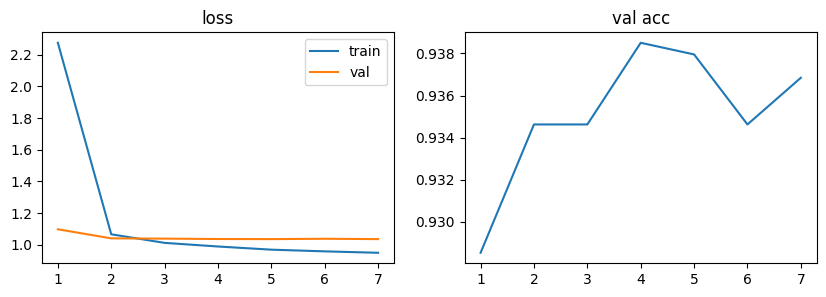

epoch 2/10


training...: 100%|██████████| 113/113 [00:13<00:00,  8.30it/s]


train loss: 1.066 used 14s


evaluating...: 100%|██████████| 29/29 [00:03<00:00,  7.67it/s]


val loss: 1.040 val acc: 0.9346
epoch 3/10


training...: 100%|██████████| 113/113 [00:13<00:00,  8.15it/s]


... (15 outputs left out)

training...: 100%|██████████| 113/113 [00:14<00:00,  8.05it/s]


train loss: 0.949 used 14s


evaluating...: 100%|██████████| 29/29 [00:03<00:00,  7.54it/s]


val loss: 1.036 val acc: 0.9368
early stop: no val acc gain for 3 epochs
best val acc: 0.9385, saved checkpoints/convnext_tiny_frozen_dd1719f110.pt


In [41]:
model_cnx = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
for p in model_cnx.parameters():
    p.requires_grad = False
model_cnx.classifier[2] = nn.Linear(model_cnx.classifier[2].in_features, len(classes))
model_cnx = model_cnx.to(device)

acc_cnx = run_experiment(name='convnext_tiny_frozen',
                         model=model_cnx,
                         train_dl=train_dl,
                         val_dl=val_dl,
                         epochs=10, lr=5e-5, patience=3)

## Dumb experiment

In [52]:
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression

# Frozen ImageNet ConvNeXt-tiny (the same backbone model_cnx uses) without the breed head -> 768-d features
backbone = model_cnx
backbone.classifier[2] = nn.Identity()

@torch.no_grad()
def extract_features(model, dl):
    device = next(model.parameters()).device
    model.eval()
    feats, labels = [], []
    for xb, yb in tqdm(dl, desc="features..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            feats.append(model(xb).float().cpu())
        labels.append(yb)
    return torch.cat(feats), torch.cat(labels)

f_train, yf_train = extract_features(backbone, train_dl)  # labels are collected with the features, so shuffling is fine
f_val, yf_val = extract_features(backbone, val_dl)
f_mean, f_std = f_train.mean(0), f_train.std(0) + 1e-6  # standardize so a unit-variance Gaussian decoder fits
f_train, f_val = (f_train - f_mean) / f_std, (f_val - f_mean) / f_std
print(f_train.shape, f_val.shape)

features...: 100%|██████████| 29/29 [00:03<00:00,  7.49it/s]


torch.Size([7217, 768]) torch.Size([1805, 768])


In [54]:
class FeatureVAE(nn.Module):
    """Class13 VAE / CVAE layout on feature vectors, with a Gaussian decoder instead of pixel BCE."""
    def __init__(self, in_dim, n_classes, latent_dim=64, hidden_dim=512, conditional=False):
        super().__init__()
        self.n_cond = n_classes if conditional else 0
        self.encoder = nn.Sequential(nn.Linear(in_dim + self.n_cond, hidden_dim), nn.ReLU())
        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim + self.n_cond, hidden_dim), nn.ReLU(),
                                     nn.Linear(hidden_dim, in_dim))

    def _cond(self, h, y):
        return torch.cat((h, F.one_hot(y, self.n_cond).to(h.dtype)), 1) if self.n_cond else h

    def encode(self, x, y=None):
        h = self.encoder(self._cond(x, y))
        return self.mu(h), self.logvar(h)

    def neg_elbo(self, x, y=None, sample=True):
        """Per-sample -ELBO: squared error / 2 (Gaussian decoder) + KL to N(0, I). sample=False decodes mu."""
        mu, logvar = self.encode(x, y)
        z = mu + (0.5 * logvar).exp() * torch.randn_like(mu) if sample else mu
        recon = self.decoder(self._cond(z, y))
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1)
        return 0.5 * (recon - x).square().sum(1) + kl

def train_feature_vae(conditional, epochs=50, lr=1e-3, bs=256):
    vae = FeatureVAE(f_train.shape[1], len(classes), conditional=conditional).to(device)
    opt = torch.optim.Adam(vae.parameters(), lr=lr)
    dl = DataLoader(torch.utils.data.TensorDataset(f_train, yf_train), batch_size=bs, shuffle=True)
    for epoch in range(epochs):
        vae.train()
        total = 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = vae.neg_elbo(xb, yb if conditional else None).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb)
        if (epoch + 1) % 10 == 0:
            vae.eval()
            with torch.no_grad():
                val = vae.neg_elbo(f_val.to(device), yf_val.to(device) if conditional else None, sample=False).mean()
            print(f"epoch {epoch + 1}: train -ELBO {total / len(f_train):.1f}  val -ELBO (mu) {val.item():.1f}")
    return vae.eval()

In [55]:
# A) CVAE as a generative classifier: score every image under every breed, keep the best ELBO + log prior.
log_prior = torch.bincount(yf_train, minlength=len(classes)).float().div(len(yf_train)).log().to(device)

@torch.no_grad()
def cvae_predict(cvae, x, bs=128):
    n = len(classes)
    preds = []
    for xb in x.split(bs):
        xb = xb.to(device)
        # rows: image 0 under breeds 0..n-1, image 1 under breeds 0..n-1, ...
        scores = -cvae.neg_elbo(xb.repeat_interleave(n, 0), torch.arange(n, device=device).repeat(len(xb)), sample=False)
        preds.append((scores.view(len(xb), n) + log_prior).argmax(1).cpu())
    return torch.cat(preds)

print("training CVAE"); cvae = train_feature_vae(conditional=True)
acc_cvae = (cvae_predict(cvae, f_val) == yf_val).float().mean().item()

# B) Unconditional VAE latent: posterior mean mu as the embedding + logistic regression (Class13 few-shot style).
print("training VAE"); vae = train_feature_vae(conditional=False)
with torch.no_grad():
    z_train, z_val = (vae.encode(f.to(device))[0].cpu().numpy() for f in (f_train, f_val))
clf = LogisticRegression(max_iter=2000).fit(z_train, yf_train.numpy())
acc_vae_lr = (clf.predict(z_val) == yf_val.numpy()).mean()

print(f"A) CVAE ELBO classifier          val acc: {acc_cvae:.4f}")
print(f"B) VAE latent + logistic regr.   val acc: {acc_vae_lr:.4f}")
print(f"reference: ConvNeXt linear head  val acc: {acc_cnx:.4f}")

training CVAE
epoch 10: train -ELBO 210.5  val -ELBO (mu) 193.1
epoch 20: train -ELBO 188.2  val -ELBO (mu) 176.2
epoch 30: train -ELBO 175.9  val -ELBO (mu) 168.9
epoch 40: train -ELBO 167.7  val -ELBO (mu) 165.1
epoch 50: train -ELBO 161.7  val -ELBO (mu) 162.4
training VAE
epoch 10: train -ELBO 220.4  val -ELBO (mu) 201.3
epoch 20: train -ELBO 203.3  val -ELBO (mu) 187.6
epoch 30: train -ELBO 196.2  val -ELBO (mu) 184.1
epoch 40: train -ELBO 191.7  val -ELBO (mu) 182.6
epoch 50: train -ELBO 188.3  val -ELBO (mu) 179.9
A) CVAE ELBO classifier          val acc: 0.9285
B) VAE latent + logistic regr.   val acc: 0.9191
reference: ConvNeXt linear head  val acc: 0.9385


## CLIP

In [58]:
!pip install -q open_clip_torch
import open_clip

clip, _, clip_tf = open_clip.create_model_and_transforms('ViT-L-14', pretrained='openai')
clip = clip.to(device).eval()
tokenizer = open_clip.get_tokenizer('ViT-L-14')

class ClipImage(nn.Module):  # lets extract_features call CLIP like any backbone
    def __init__(self, clip):
        super().__init__()
        self.clip = clip

    def forward(self, x):
        return self.clip.encode_image(x)

def clip_dl(X, labels):  # CLIP has its own resize/normalize, not the ImageNet one
    return DataLoader(DogDataset(X, labels, clip_tf), batch_size=BS, num_workers=2)

clip_backbone = ClipImage(clip)
fc_train, yc_train = extract_features(clip_backbone, clip_dl(X_train, y_train))
fc_val, yc_val = extract_features(clip_backbone, clip_dl(X_val, y_val))

with torch.no_grad():
    text = clip.encode_text(tokenizer([f"a photo of a {c.replace('_', ' ')}, a type of dog." for c in classes]).to(device))
text = text / text.norm(dim=-1, keepdim=True)
img = fc_val.to(device)
img = img / img.norm(dim=-1, keepdim=True)
acc_clip_zs = ((img @ text.T).argmax(1).cpu() == yc_val).float().mean().item()
print(f"CLIP zero-shot val acc: {acc_clip_zs:.4f}")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
features...: 100%|██████████| 29/29 [00:20<00:00,  1.42it/s]


CLIP zero-shot val acc: 0.7030


In [59]:
# Reuse the CVAE code above by pointing its feature variables at the CLIP features.
# This overwrites the ConvNeXt features: re-run the VAE / CVAE section to get them back.
f_mean, f_std = fc_train.mean(0), fc_train.std(0) + 1e-6
f_train, yf_train = (fc_train - f_mean) / f_std, yc_train
f_val, yf_val = (fc_val - f_mean) / f_std, yc_val

print("training CVAE on CLIP features"); cvae_clip = train_feature_vae(conditional=True)
acc_cvae_clip = (cvae_predict(cvae_clip, f_val) == yf_val).float().mean().item()
print(f"CLIP + CVAE val acc: {acc_cvae_clip:.4f}  (ConvNeXt + CVAE: {acc_cvae:.4f}, ConvNeXt head: {acc_cnx:.4f})")

training CVAE on CLIP features
epoch 10: train -ELBO 216.4  val -ELBO (mu) 198.9
epoch 20: train -ELBO 195.6  val -ELBO (mu) 183.9
epoch 30: train -ELBO 185.6  val -ELBO (mu) 178.9
epoch 40: train -ELBO 179.3  val -ELBO (mu) 176.4
epoch 50: train -ELBO 174.9  val -ELBO (mu) 174.8
CLIP + CVAE val acc: 0.8111  (ConvNeXt + CVAE: 0.9285, ConvNeXt head: 0.9385)


## Combined many features

In [63]:
# Unshuffled loaders: every backbone must list the images in the same order before the vectors are joined
ordered = lambda X, labels: DataLoader(DogDataset(X, labels, val_tf), batch_size=BS, num_workers=2)

resnet_backbone = copy.deepcopy(model_baseline)  # frozen ImageNet ResNet50, breed head removed
resnet_backbone.fc = nn.Identity()

stack_sources = {  # name -> (backbone, loader with that backbone's preprocessing)
    'resnet50': (resnet_backbone, ordered),
    'convnext_tiny': (backbone, ordered),  # ConvNeXt-tiny without head, from the VAE / CVAE section
    'clip_vit_l14': (clip_backbone, clip_dl),
}
feats = {split: {} for split in ('train', 'val', 'test')}
for name, (bb, make_dl) in stack_sources.items():
    for split, X, labels in (('train', X_train, y_train), ('val', X_val, y_val), ('test', fns_submit, None)):
        feats[split][name] = extract_features(bb, make_dl(X, labels))[0].numpy()
    print(name, feats['train'][name].shape)

features...: 100%|██████████| 19/19 [00:03<00:00,  5.75it/s]


resnet50 (7217, 2048)


features...: 100%|██████████| 19/19 [00:03<00:00,  5.57it/s]


convnext_tiny (7217, 768)


features...: 100%|██████████| 19/19 [00:14<00:00,  1.36it/s]

clip_vit_l14 (7217, 768)


In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def stack(split, names):
    return np.hstack([feats[split][n] for n in names])

def fit_lr(names, C=0.1):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    clf.fit(stack('train', names), y_train)
    return clf, (clf.predict(stack('val', names)) == y_val).mean()

# Each backbone alone, then all of them stacked (takes a few minutes on CPU)
for name in stack_sources:
    print(f"{name:15s} alone   val acc: {fit_lr([name])[1]:.4f}")
stack_clf, acc_stack = fit_lr(list(stack_sources))
print(f"{'stacked':15s} {stack('train', stack_sources).shape[1]} dims  val acc: {acc_stack:.4f}")
print(f"reference: ConvNeXt linear head  val acc: {acc_cnx:.4f}")

resnet50        alone   val acc: 0.8399
convnext_tiny   alone   val acc: 0.9341
clip_vit_l14    alone   val acc: 0.8216
stacked         3584 dims  val acc: 0.9252
reference: ConvNeXt linear head  val acc: 0.9385


## Generating the answer to submit:

In [60]:
@torch.no_grad()
def predict_proba(model, dl):
    device = next(model.parameters()).device
    model.eval()
    out = []
    for xb, _ in tqdm(dl, desc="predicting..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            out.append(model(xb).float().softmax(1).cpu())
    return torch.cat(out).numpy()

singles = [(acc_baseline, model_baseline), (acc_aug, model_aug), (acc_ft, model_ft), (acc_cnx, model_cnx)]
acc, best_model = max(singles, key=lambda t: t[0])
print(f"submitting the best single model, val acc {acc:.4f}")
probs = predict_proba(best_model, test_dl)
y_submit = [str(classes[i]) for i in probs.argmax(1)]  # breed names, like the labels in y
assert len(y_submit) == len(fns_submit)

submitting the best single model, val acc 0.9385


predicting...: 100%|██████████| 19/19 [00:03<00:00,  5.55it/s]


IndexError: index 145 is out of bounds for axis 0 with size 120

In [61]:
# Alternative: submit the CLIP + CVAE model. Running this overwrites y_submit from the cell above.
fc_test, _ = extract_features(clip_backbone, clip_dl(fns_submit, None))  # not shuffled, so same order as fns_submit
y_submit = [str(c) for c in classes[cvae_predict(cvae_clip, (fc_test - f_mean) / f_std).numpy()]]
assert len(y_submit) == len(fns_submit)

features...: 100%|██████████| 19/19 [00:13<00:00,  1.43it/s]


In [65]:
# Alternative: submit the stacked-features logistic regression. Running this overwrites y_submit.
y_submit = [str(c) for c in classes[stack_clf.predict(stack('test', stack_sources))]]
assert len(y_submit) == len(fns_submit)

In [66]:
answer_to_submit = {fn: label for fn, label in zip(fns_submit, y_submit)}
with open('my_answer_dogs.pkl', 'wb') as f:
    pkl.dump((answer_to_submit, uuid.uuid4().hex, time()), f)

Now submit your result to yandex contest and let us see the score.